# Problem Statement

## UIDAI Aadhaar Enrolment & Update Pattern Analysis

### India's Unique Identification Authority (UIDAI) issues Aadhaar numbers and manages mandatory updates (biometric re-capture at ages 5 and 15, demographic corrections, etc.) across the country. With enrolment/update centers spread across thousands of pincodes, UIDAI and policymakers need visibility into:

* Where new enrolments are concentrated (which states/districts still have unregistered populations, especially children)
* Where update-center load is highest (to plan staffing/capacity)
* How activity is split between first-time enrolment vs mandatory updates by age group
* Whether there are seasonal, weekly, or regional patterns that could inform resource allocation

#### What the Data Is About

##### Each row = one district/pincode, on one date, with counts of:

* New Aadhaar enrolments, split by age band (0-5, 5-17, 18+)
* Demographic update requests, split by age band
* Biometric update requests, split by age band

It spans April 2025 – September 2025, across 46 states/UTs, 880 districts, 17,560 pincodes (~95,000 rows).

| Column | Type | Description |
|---|---|---|
| date | Date | Date of the recorded transactions (Apr–Sep 2025) |
| state | Text | State/UT name |
| district | Text | District name |
| pincode | Numeric | 6-digit postal code of the enrolment/update center area |
| age_0_5 | Numeric | New Aadhaar enrolments for children aged 0–5 |
| age_5_17 | Numeric | New Aadhaar enrolments for ages 5–17 |
| age_18_greater | Numeric | New Aadhaar enrolments for ages 18+ |
| demo_age_5_17 | Numeric | Demographic update requests (name/address/DOB etc.) for ages 5–17 |
| demo_age_17_ | Numeric | Demographic update requests for ages 17+ |
| bio_age_5_17 | Numeric | Biometric update requests (fingerprint/iris/photo) for ages 5–17 |
| bio_age_17_ | Numeric | Biometric update requests for ages 17+ |

# 1. Importing necessary library

In [177]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# 2. Load & Inspect Data

In [124]:
df = pd.read_csv("UIDAI.csv")

In [125]:
df.head()

,Unnamed: 0,date,state,district,pincode,age_0_5,age_5_17,age_18_greater,demo_age_5_17,demo_age_17_,bio_age_5_17,bio_age_17_
0,0,2025-04-01,Tamil Nadu,Kancheepuram,600045,81,19,14,53,502,193,271
1,1,2025-04-01,Rajasthan,Jhalawar,326038,112,49,12,76,588,152,327
2,2,2025-04-01,Madhya Pradesh,Raisen,464551,291,39,12,213,1030,1989,753
3,3,2025-04-01,Madhya Pradesh,Dhar,454001,253,74,75,372,1804,1775,1583
4,4,2025-04-01,Chandigarh,Chandigarh,160036,86,21,10,400,1441,542,426


In [126]:
df.tail()

,Unnamed: 0,date,state,district,pincode,age_0_5,age_5_17,age_18_greater,demo_age_5_17,demo_age_17_,bio_age_5_17,bio_age_17_
94950,94950,2025-09-19,Delhi,South Delhi,110017,1,0,0,4,48,17,32
94951,94951,2025-09-19,Delhi,North West Delhi,110081,15,1,0,12,38,70,80
94952,94952,2025-09-19,Delhi,North West Delhi,110052,4,0,0,6,48,25,18
94953,94953,2025-09-19,Delhi,North West Delhi,110036,4,1,0,1,23,23,35
94954,94954,2025-09-19,Delhi,North West Delhi,110082,2,0,0,2,12,4,11


In [127]:
df.sample(5)

,Unnamed: 0,date,state,district,pincode,age_0_5,age_5_17,age_18_greater,demo_age_5_17,demo_age_17_,bio_age_5_17,bio_age_17_
39101,39101,2025-09-09,Punjab,Gurdaspur,143515,1,0,0,0,12,6,10
54205,54205,2025-09-11,Punjab,Ludhiana,141013,7,2,0,3,38,20,13
93279,93279,2025-09-19,Karnataka,Mysore,570010,1,0,0,0,4,0,1
79658,79658,2025-09-16,Gujarat,Ahmadabad,380001,2,1,0,0,24,1,23
43027,43027,2025-09-09,Maharashtra,Mumbai,400081,2,0,0,0,7,2,14


In [128]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94955 entries, 0 to 94954
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Unnamed: 0      94955 non-null  int64 
 1   date            94955 non-null  object
 2   state           94955 non-null  object
 3   district        94955 non-null  object
 4   pincode         94955 non-null  int64 
 5   age_0_5         94955 non-null  int64 
 6   age_5_17        94955 non-null  int64 
 7   age_18_greater  94955 non-null  int64 
 8   demo_age_5_17   94955 non-null  int64 
 9   demo_age_17_    94955 non-null  int64 
 10  bio_age_5_17    94955 non-null  int64 
 11  bio_age_17_     94955 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 8.7+ MB


In [129]:
df.describe()

,Unnamed: 0,pincode,age_0_5,age_5_17,age_18_greater,demo_age_5_17,demo_age_17_,bio_age_5_17,bio_age_17_
count,94955.000000,94955.00000,94955.000000,94955.000000,94955.000000,94955.000000,94955.000000,94955.000000,94955.000000
mean,47477.000000,516986.25906,4.315802,2.028929,0.106250,3.524585,28.831099,15.804655,14.014270
std,27411.291743,206818.78222,29.076013,16.433080,1.450567,23.669851,184.133758,86.564516,89.234521
min,0.000000,110001.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23738.500000,363423.00000,1.000000,0.000000,0.000000,0.000000,5.000000,2.000000,3.000000
50%,47477.000000,509408.00000,2.000000,1.000000,0.000000,1.000000,12.000000,5.000000,6.000000
75%,71215.500000,711403.50000,4.000000,2.000000,0.000000,3.000000,26.000000,14.000000,13.000000
max,94954.000000,855117.00000,2688.000000,1351.000000,151.000000,1883.000000,14732.000000,5854.000000,7201.000000


In [130]:
df.describe(include ='object')

,date,state,district
count,94955,94955,94955
unique,23,46,880
top,2025-09-10,Uttar Pradesh,Pune
freq,7718,10122,731


#### check missing values

In [131]:
df.isnull().sum()

Unnamed: 0        0
date              0
state             0
district          0
pincode           0
age_0_5           0
age_5_17          0
age_18_greater    0
demo_age_5_17     0
demo_age_17_      0
bio_age_5_17      0
bio_age_17_       0
dtype: int64

#### check Duplicated values

In [132]:
df.duplicated().sum()

np.int64(0)

# 3. Data Cleaning



In [165]:
state_mapping = {
    'Orissa': 'Odisha',
    'Pondicherry': 'Puducherry',
    'Andaman & Nicobar Islands': 'Andaman and Nicobar Islands',
    'Dadra & Nagar Haveli': 'Dadra and Nagar Haveli',
    'Jammu & Kashmir': 'Jammu and Kashmir',
    'Daman & Diu': 'Daman and Diu',
    'Westbengal': 'West Bengal',
    'andhra pradesh': 'Andhra Pradesh'
}

In [166]:
df['state'] = (
    df['state']
    .str.strip()
    .replace(state_mapping)
)

In [167]:
df['state'].value_counts()

state
Uttar Pradesh                               10122
Maharashtra                                  8321
Tamil Nadu                                   7295
Karnataka                                    6975
West Bengal                                  6741
Andhra Pradesh                               5824
Rajasthan                                    5649
Bihar                                        5613
Odisha                                       5267
Madhya Pradesh                               5174
Gujarat                                      4425
Telangana                                    3710
Kerala                                       3498
Assam                                        3104
Jharkhand                                    2381
Punjab                                       2176
Chhattisgarh                                 1644
Haryana                                      1637
Jammu and Kashmir                            1040
Himachal Pradesh                            

In [168]:
df['date'] = pd.to_datetime(df['date'])

#### Checking outliers

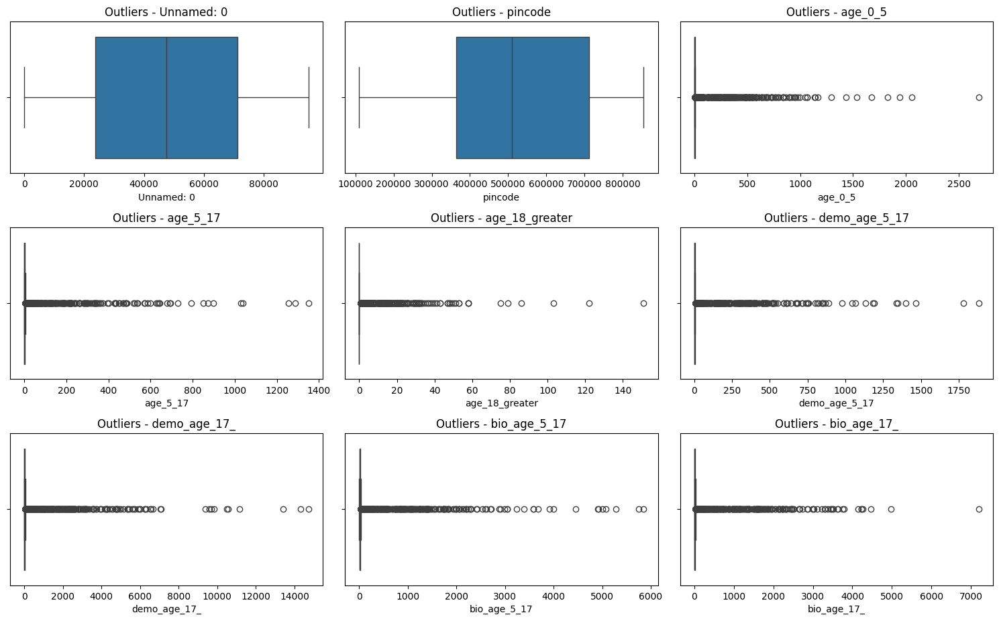

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(15, 12))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f'Outliers - {col}')

plt.tight_layout()
plt.show()

#### feature Engineering

In [139]:
df.drop(['Unnamed: 0','pincode'],inplace= True, axis = 1)

In [140]:
df['total_enrolment'] = df['age_0_5'] + df['age_5_17'] + df['age_18_greater']
df['total_demo_update'] = df['demo_age_5_17'] + df['demo_age_17_']
df['total_bio_update'] = df['bio_age_5_17'] + df['bio_age_17_']
df['total_activity'] = df['total_enrolment'] + df['total_demo_update'] + df['total_bio_update']
df['month'] = df['date'].dt.month_name()
df['weekday'] = df['date'].dt.day_name()

In [141]:
df.head()

,date,state,district,age_0_5,age_5_17,age_18_greater,demo_age_5_17,demo_age_17_,bio_age_5_17,bio_age_17_,total_enrolment,total_demo_update,total_bio_update,total_activity,month,weekday
0,2025-04-01,Tamil Nadu,Kancheepuram,81,19,14,53,502,193,271,114,555,464,1133,April,Tuesday
1,2025-04-01,Rajasthan,Jhalawar,112,49,12,76,588,152,327,173,664,479,1316,April,Tuesday
2,2025-04-01,Madhya Pradesh,Raisen,291,39,12,213,1030,1989,753,342,1243,2742,4327,April,Tuesday
3,2025-04-01,Madhya Pradesh,Dhar,253,74,75,372,1804,1775,1583,402,2176,3358,5936,April,Tuesday
4,2025-04-01,Chandigarh,Chandigarh,86,21,10,400,1441,542,426,117,1841,968,2926,April,Tuesday


# 4. Data Analysis

## 1.Univariate analysis

In [142]:
print("Date range:", df['date'].min().date(), "to", df['date'].max().date())
print("States:", df['state'].nunique())
print("Districts:", df['district'].nunique())

Date range: 2025-04-01 to 2025-09-19
States: 38
Districts: 880


## 2.Univariate analysis

### 1. Enrollment vs Update Dependency

In [143]:
## Which districts have unusually high update activity compared with new enrolments?
district_analysis = df.groupby('district').agg(
    total_enrolment=('total_enrolment', 'sum'),
    total_demo_update=('total_demo_update', 'sum'),
    total_bio_update=('total_bio_update', 'sum'),
    total_activity=('total_activity', 'sum')
).reset_index()

district_analysis['update_to_enrolment_ratio'] = (
    (district_analysis['total_demo_update'] +
     district_analysis['total_bio_update']) /
    district_analysis['total_enrolment']
)

district_analysis.sort_values(
    'update_to_enrolment_ratio',
    ascending=False
).head(10)


,district,total_enrolment,total_demo_update,total_bio_update,total_activity,update_to_enrolment_ratio
798,Thoubal,69,2399,863,3331,47.275362
373,Kamle,1,38,4,43,42.000000
118,Bishnupur,54,828,910,1792,32.185185
419,Kishanganj,1026,25997,5977,33000,31.163743
317,Imphal East,64,729,1136,1929,29.140625
318,Imphal West,100,978,1775,2853,27.530000
60,Balod,202,2328,3131,5661,27.024752
178,Dakshin Bastar Dantewada,42,295,827,1164,26.714286
698,Sarangarh-Bilaigarh,2,38,14,54,26.000000
102,Bhandara,195,1113,3841,5149,25.405128


### 2.Demographic vs Biometric Update Relationship

In [144]:
df[['total_demo_update', 'total_bio_update']].corr()

,total_demo_update,total_bio_update
total_demo_update,1.000000,0.903534
total_bio_update,0.903534,1.000000


In [145]:
df['demo_bio_ratio'] = (
    df['total_demo_update'] /
    (df['total_bio_update'] + 1)
)

In [146]:
df['demo_bio_ratio']

0        1.193548
1        1.383333
2        0.453153
3        0.647812
4        1.899897
           ...   
94950    1.040000
94951    0.331126
94952    1.227273
94953    0.406780
94954    0.875000
Name: demo_bio_ratio, Length: 94955, dtype: float64

In [147]:
df.groupby('state')['demo_bio_ratio'].mean().sort_values(ascending=False)

state
Bihar                                       3.782284
Dadra and Nagar Haveli and Daman and Diu    3.603351
West Bengal                                 3.422985
Meghalaya                                   2.702949
Telangana                                   2.382055
Sikkim                                      2.331654
Uttar Pradesh                               2.090851
Assam                                       2.052554
Daman and Diu                               1.900000
Jharkhand                                   1.776589
Arunachal Pradesh                           1.721298
Manipur                                     1.524810
Himachal Pradesh                            1.510236
Tripura                                     1.478772
Chhattisgarh                                1.348089
Andhra Pradesh                              1.302442
Chandigarh                                  1.293420
Tamil Nadu                                  1.256781
Goa                                     

* States dominated by demographic corrections
* States dominated by biometric updates
* States with balanced update requirements

### 3. Child Enrollment vs Adult Enrollmen

In [148]:
#Which states have relatively higher child enrolment activity?
df['child_adult_ratio'] = (
    (df['age_0_5'] + df['age_5_17']) /
    (df['age_18_greater'] + 1)
)

In [149]:
df.groupby('state')['child_adult_ratio'].mean().sort_values(
    ascending=False
).head(10)

state
Delhi             8.789779
Madhya Pradesh    8.619207
Bihar             7.324781
Uttar Pradesh     7.097261
Rajasthan         6.577820
Jharkhand         6.330993
Assam             5.182090
Chhattisgarh      4.847231
West Bengal       4.828197
Haryana           4.604893
Name: child_adult_ratio, dtype: float64

### 4.High Activity but Low Enrolment

In [150]:
district = df.groupby('district').agg(
    enrolment=('total_enrolment', 'sum'),
    updates=('total_demo_update', 'sum')
).reset_index()

district['update_percentage'] = (
    district['updates'] /
    (district['enrolment'] + district['updates']) * 100
)

district.sort_values(
    'update_percentage',
    ascending=False
).head(15)

,district,enrolment,updates,update_percentage
373,Kamle,1,38,97.435897
798,Thoubal,69,2399,97.204214
419,Kishanganj,1026,25997,96.203234
544,Nalanda,1062,23001,95.586585
514,Mohla-Manpur-Ambagarh Chouki,21,427,95.312500
698,Sarangarh-Bilaigarh,2,38,95.000000
333,Jalpaiguri,944,17720,94.942135
847,Warangal Rural,65,1113,94.482173
403,Kawardha,213,3603,94.418239
839,Vikarabad,249,3930,94.041637


### 5.State × Month: Detect Changing Demand

In [151]:
monthly = (
    df.groupby(['state', 'month'])['total_activity']
      .sum()
      .reset_index()
      .sort_values(by='total_activity', ascending=False)
)

In [152]:
monthly

,state,month,total_activity
80,Uttar Pradesh,September,852179
9,Bihar,September,580443
52,Maharashtra,September,565428
69,Rajasthan,September,400176
86,West Bengal,September,384626
...,...,...,...
0,Andaman and Nicobar Islands,September,523
17,Dadra and Nagar Haveli and Daman and Diu,September,205
41,Ladakh,September,157
42,Lakshadweep,September,115


### 6.6. Weekday × Activity Intensity

In [153]:
weekday_analysis = df.groupby('weekday').agg(
    avg_activity=('total_activity', 'mean'),
    total_activity=('total_activity', 'sum')
).sort_values('avg_activity', ascending=False)

weekday_analysis

,avg_activity,total_activity
weekday,,
Sunday,124.612817,280005
Tuesday,114.500327,1927384
Thursday,74.972256,1118736
Monday,55.266747,1060182
Wednesday,52.743950,991639
Friday,50.192581,691453
Saturday,48.617861,446944


### 7.District Activity Profiling

In [154]:
profile = df.groupby('district').agg(
    enrolment=('total_enrolment', 'sum'),
    demo=('total_demo_update', 'sum'),
    bio=('total_bio_update', 'sum'),
    child=('age_0_5', 'sum'),
    adult=('age_18_greater', 'sum')
).reset_index()

profile['enrolment_%'] = (
    profile['enrolment'] / profile['enrolment'].sum() * 100
)

profile['demo_%'] = (
    profile['demo'] /
    (profile['demo'] + profile['bio']) * 100
)

profile['bio_%'] = (
    profile['bio'] /
    (profile['demo'] + profile['bio']) * 100
)

In [155]:
profile

,district,enrolment,demo,bio,child,adult,enrolment_%,demo_%,bio_%
0,Adilabad,530,3016,3297,435,0,0.086523,47.774434,52.225566
1,Agar Malwa,157,345,468,100,0,0.025630,42.435424,57.564576
2,Agra,3164,16950,11434,1817,39,0.516527,59.716742,40.283258
3,Ahmadabad,78,283,309,49,0,0.012734,47.804054,52.195946
4,Ahmadnagar,1141,3942,18353,724,15,0.186270,17.681094,82.318906
...,...,...,...,...,...,...,...,...,...
875,Yavatmal,667,3572,11532,525,10,0.108889,23.649364,76.350636
876,Zunheboto,33,171,268,8,3,0.005387,38.952164,61.047836
877,chittoor,1,1,1,1,0,0.000163,50.000000,50.000000
878,jajpur,4,2,3,2,0,0.000653,40.000000,60.000000


## 2. Multivariate Analysis

### 1.State × Month × Enrollment

In [156]:
state_month = pd.pivot_table(
    df,
    index='state',
    columns='month',
    values='total_enrolment',
    aggfunc='sum',
    fill_value=0
)

state_month

month,April,July,June,May,September
state,,,,,
Andaman and Nicobar Islands,0,0,0,0,49
Andhra Pradesh,0,0,0,0,11621
Arunachal Pradesh,0,0,0,0,585
Assam,203,2139,227,0,17012
Bihar,641,0,0,1188,43129
Chandigarh,117,0,0,0,185
Chhattisgarh,706,495,0,544,8096
Dadra and Nagar Haveli,0,0,0,0,46
Dadra and Nagar Haveli and Daman and Diu,0,0,0,0,16


### 2. State × Age Group × Month

In [170]:
age_month = df.groupby(
    ['state', 'month']
)[['age_0_5', 'age_5_17', 'age_18_greater']].sum()

age_month

age_0_5  age_5_17  age_18_greater
state                       month                                       
Andaman and Nicobar Islands September       45         4               0
Andhra Pradesh              September    10107      1440              74
Arunachal Pradesh           September      304       281               0
Assam                       April          135        47              21
                            July          1560       461             118
...                                        ...       ...             ...
Uttarakhand                 May            477       135              12
                            September     2173       412              13
West Bengal                 April          289        89              20
                            May            860       741              42
                            September    25866      7578             350

[87 rows x 3 columns]

###  3.State × Age Group × Update Type

In [175]:
age_update = df.groupby('state')[
    ['age_0_5', 'age_5_17', 'age_18_greater',
     'total_demo_update', 'total_bio_update']
].sum()

age_update

,age_0_5,age_5_17,age_18_greater,total_demo_update,total_bio_update
state,,,,,
Andaman and Nicobar Islands,45,4,0,152,322
Andhra Pradesh,10107,1440,74,60445,52720
Arunachal Pradesh,304,281,0,3028,2171
Assam,13843,5311,427,69304,39359
Bihar,19463,25136,359,412894,136494
Chandigarh,251,41,10,3223,2087
Chhattisgarh,8155,1526,160,75740,76084
Dadra and Nagar Haveli,41,5,0,325,936
Dadra and Nagar Haveli and Daman and Diu,13,3,0,151,38


# 5.Data Visualization

# 1. Univariate Visualization1

### Top 15 States by Enrolment

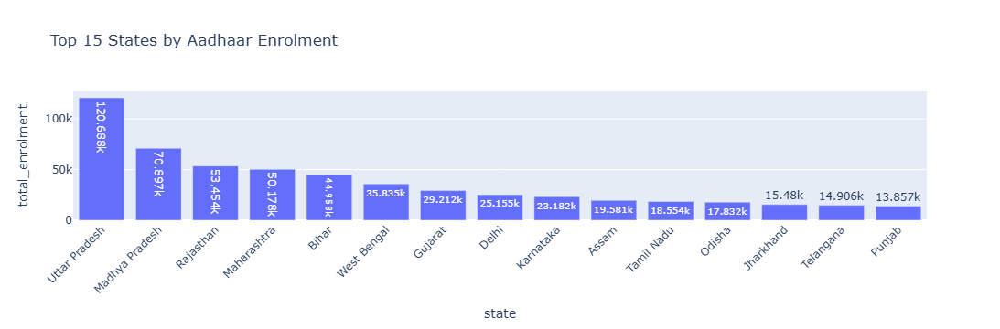

In [182]:
state_enrolment = (
    df.groupby('state')['total_enrolment']
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

fig = px.bar(
    state_enrolment,
    x='state',
    y='total_enrolment',
    title='Top 15 States by Aadhaar Enrolment',
    text_auto=True
)

fig.update_layout(xaxis_tickangle=-45)

fig.show()

### Monthly Enrolment Trend

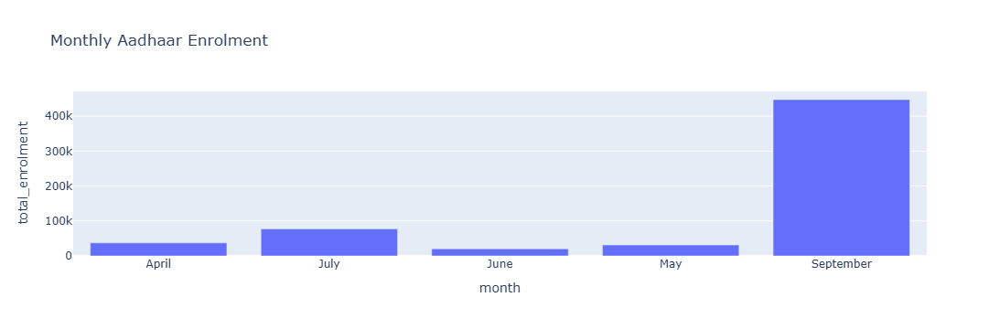

In [199]:
monthly_enrolment = (
    df.groupby('month')['total_enrolment']
    .sum()
    .reset_index()
)

fig = px.bar(
    monthly_enrolment,
    x='month',
    y='total_enrolment',
    title='Monthly Aadhaar Enrolment'
)

fig.show()

## 2. Bivariate Visualizations


#### Monthly Enrolment Trend

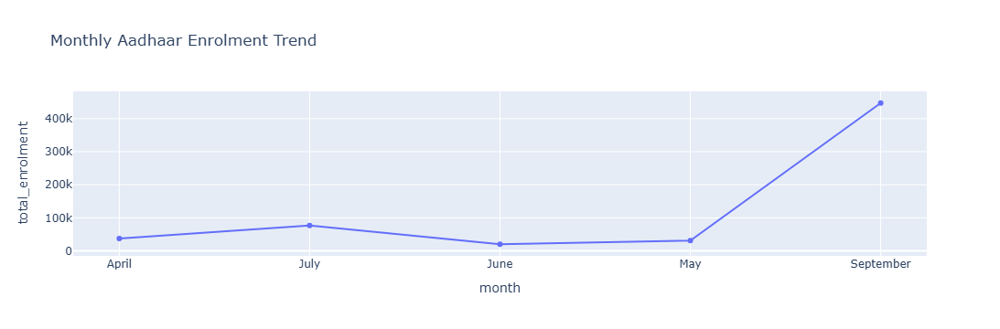

In [198]:
monthly = df.groupby('month')['total_enrolment'].sum().reset_index()

fig = px.line(
    monthly,
    x='month',
    y='total_enrolment',
    markers=True,
    title='Monthly Aadhaar Enrolment Trend'
)

fig.show()

### Top 10 States by Enrolment

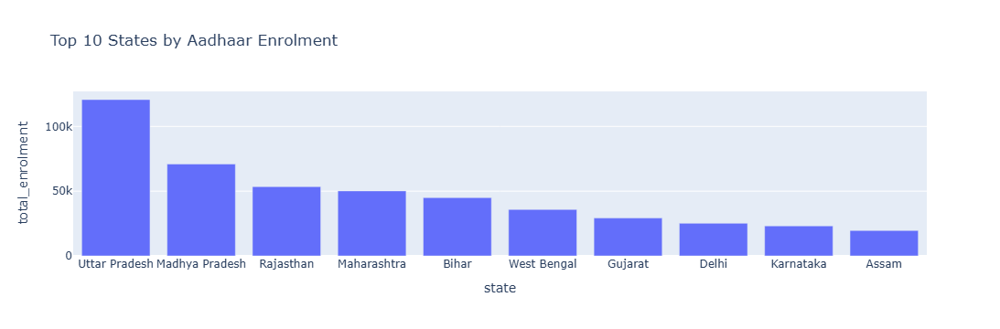

In [200]:
state_enrolment = (
    df.groupby('state')['total_enrolment']
    .sum()
    .nlargest(10)
    .reset_index()
)

fig = px.bar(
    state_enrolment,
    x='state',
    y='total_enrolment',
    title='Top 10 States by Aadhaar Enrolment'
)

fig.show()

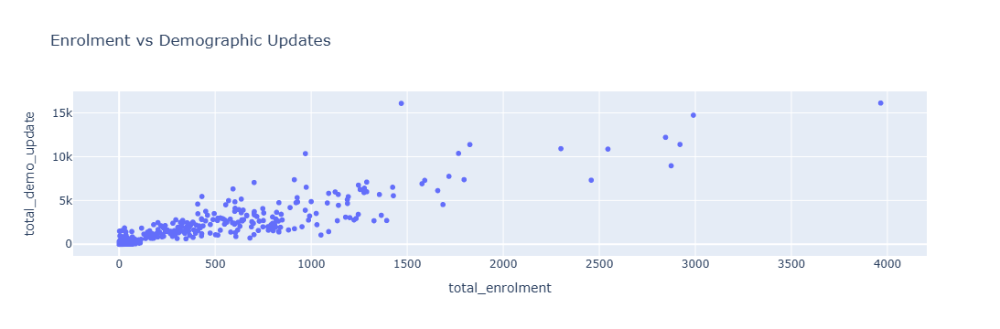

In [184]:
fig = px.scatter(
    df,
    x='total_enrolment',
    y='total_demo_update',
    title='Enrolment vs Demographic Updates',
    hover_data=['state', 'district']
)

fig.show()

### Enrolment vs Biometric Updates

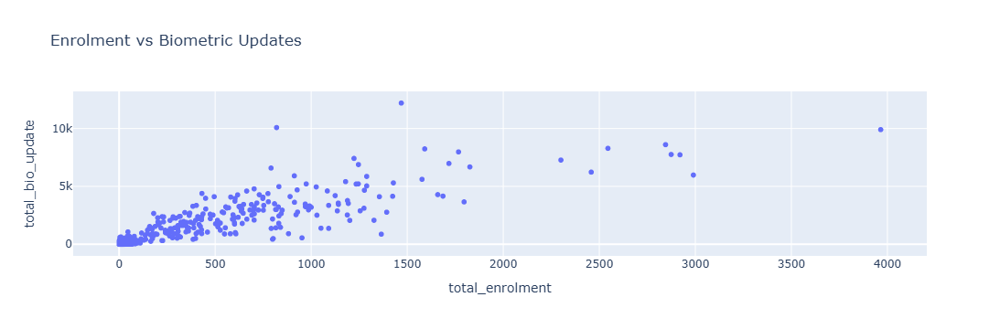

In [185]:
fig = px.scatter(
    df,
    x='total_enrolment',
    y='total_bio_update',
    title='Enrolment vs Biometric Updates',
    hover_data=['state', 'district']
)

fig.show()

### Age Group Comparison

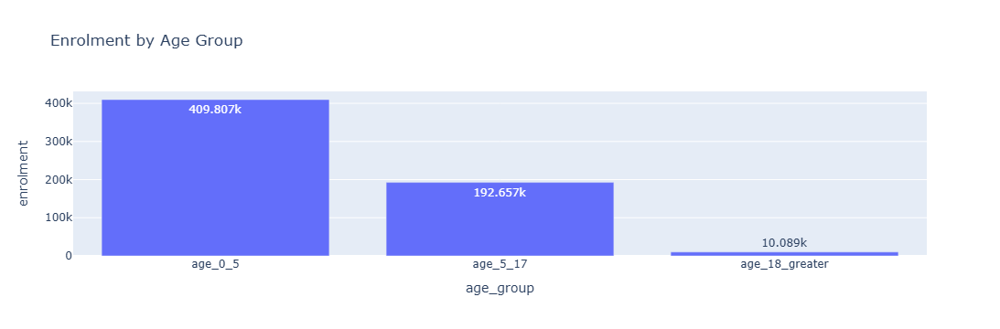

In [186]:
age_data = df[
    ['age_0_5', 'age_5_17', 'age_18_greater']
].sum().reset_index()

age_data.columns = ['age_group', 'enrolment']

fig = px.bar(
    age_data,
    x='age_group',
    y='enrolment',
    title='Enrolment by Age Group',
    text_auto=True
)

fig.show()

## 3.Multivariate Visualizations

### State × Month × Enrolment

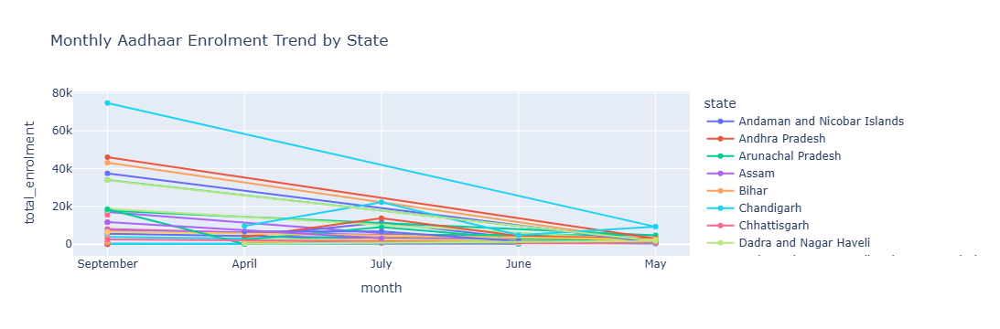

In [187]:
state_month = (
    df.groupby(['state', 'month'])['total_enrolment']
    .sum()
    .reset_index()
)

fig = px.line(
    state_month,
    x='month',
    y='total_enrolment',
    color='state',
    markers=True,
    title='Monthly Aadhaar Enrolment Trend by State'
)

fig.show()

### State × Month × Update Type

In [190]:
top_states = (
    df.groupby('state')['total_demo_update']
    .sum()
    .nlargest(5)
    .index
)

update_data = (
    df[df['state'].isin(top_states)]
    .groupby(['state', 'month'])[
        ['total_demo_update', 'total_bio_update']
    ]
    .sum()
    .reset_index()
)

update_data = update_data.melt(
    id_vars=['state', 'month'],
    value_vars=['total_demo_update', 'total_bio_update'],
    var_name='update_type',
    value_name='updates'
)

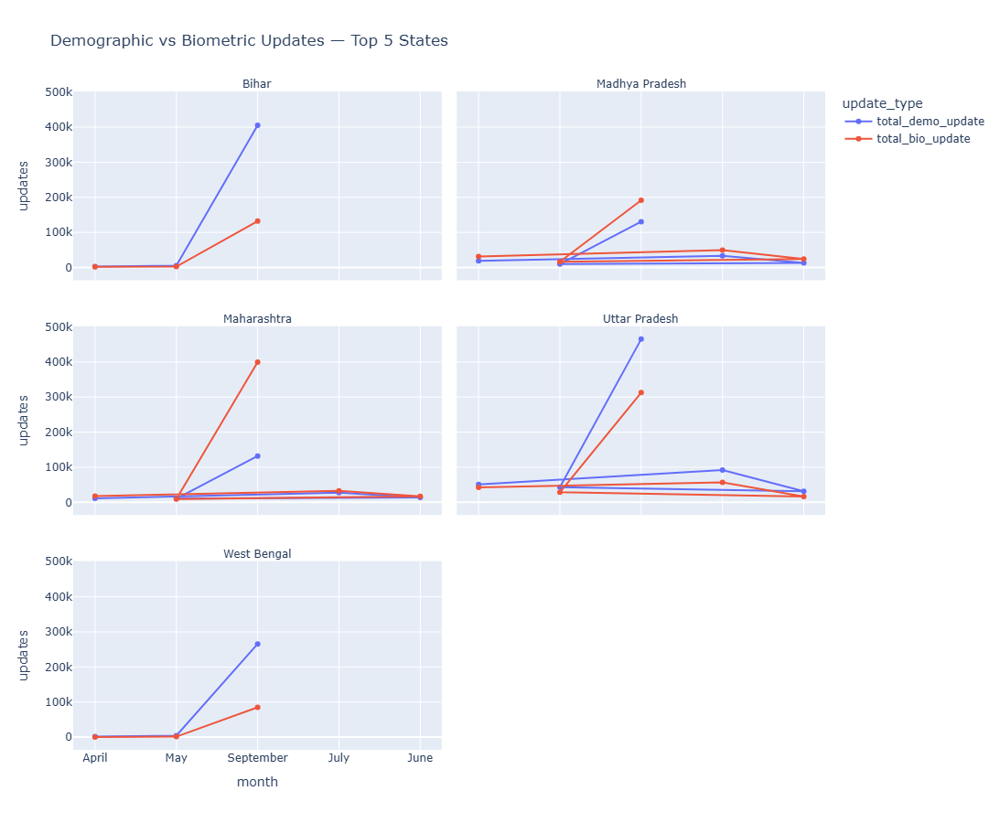

In [191]:
fig = px.line(
    update_data,
    x='month',
    y='updates',
    color='update_type',
    facet_col='state',
    facet_col_wrap=2,
    markers=True,
    title='Demographic vs Biometric Updates — Top 5 States'
)

fig.update_layout(
    height=900
)

fig.for_each_annotation(
    lambda a: a.update(text=a.text.split("=")[-1])
)

fig.show()

### Age Group × State × Enrolment

In [192]:
age_state = df.groupby('state')[
    ['age_0_5', 'age_5_17', 'age_18_greater']
].sum().reset_index()

age_state = age_state.melt(
    id_vars='state',
    var_name='age_group',
    value_name='enrolment'
)

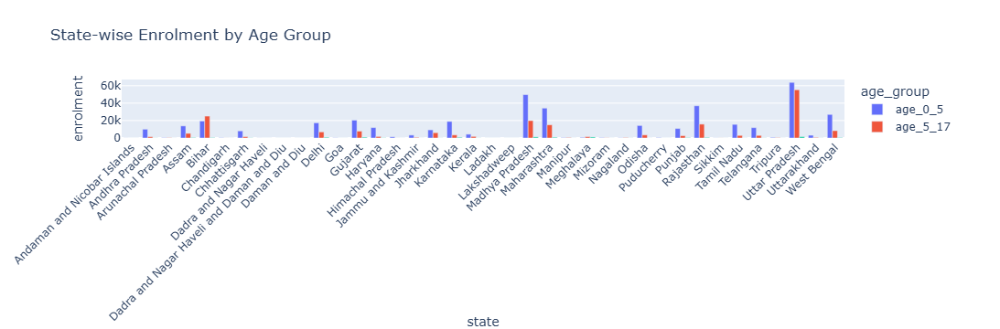

In [193]:
fig = px.bar(
    age_state,
    x='state',
    y='enrolment',
    color='age_group',
    barmode='group',
    title='State-wise Enrolment by Age Group'
)

fig.update_layout(xaxis_tickangle=-45)

fig.show()

### District × Enrolment × Updates

In [195]:
district_data = df.groupby('district').agg(
    enrolment=('total_enrolment', 'sum'),
    demo_update=('total_demo_update', 'sum'),
    bio_update=('total_bio_update', 'sum')
).reset_index()

district_data['total_updates'] = (
    district_data['demo_update'] +
    district_data['bio_update']
)

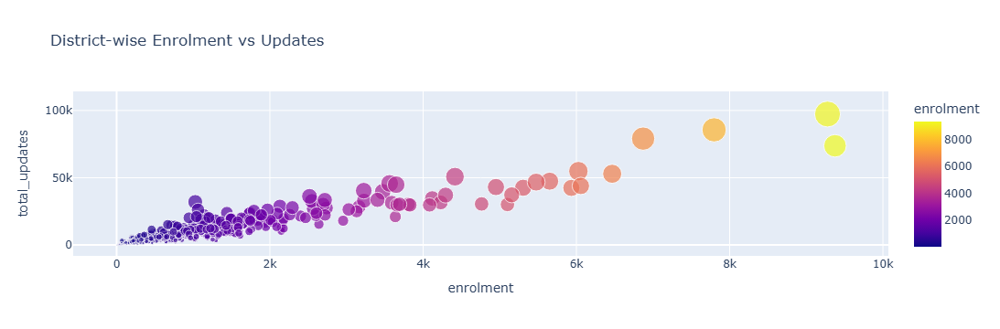

In [196]:
fig = px.scatter(
    district_data,
    x='enrolment',
    y='total_updates',
    size='total_updates',
    color='enrolment',
    hover_name='district',
    title='District-wise Enrolment vs Updates'
)

fig.show()

In [201]:
numeric_cols = [
    'age_0_5', 'age_5_17', 'age_18_greater', 
    'demo_age_5_17', 'demo_age_17_', 
    'bio_age_5_17', 'bio_age_17_', 
    'total_enrolment', 'total_demo_update', 'total_bio_update', 'total_activity'
]

univariate_records = []
for col in numeric_cols:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    outliers = s[s > upper_fence]
    
    univariate_records.append({
        'Metric': col,
        'Mean': s.mean(),
        'Median': s.median(),
        'Std Dev': s.std(),
        'Skewness': s.skew(),
        'Kurtosis': s.kurtosis(),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': iqr,
        'Upper Fence': upper_fence,
        'Outlier Count': len(outliers),
        'Outlier %': (len(outliers) / len(s)) * 100
    })

univariate_df = pd.DataFrame(univariate_records)
univariate_df.sort_values('Skewness', ascending=False)

,Metric,Mean,Median,Std Dev,Skewness,Kurtosis,Q1 (25%),Q3 (75%),IQR,Upper Fence,Outlier Count,Outlier %
1,age_5_17,2.028929,1.0,16.433080,42.248395,2348.058247,0.0,2.0,2.0,5.0,6384,6.723185
2,age_18_greater,0.106250,0.0,1.450567,40.735389,2676.054244,0.0,0.0,0.0,0.0,3481,3.665947
4,demo_age_17_,28.831099,12.0,184.133758,39.566022,2126.375269,5.0,26.0,21.0,57.5,8084,8.513506
8,total_demo_update,32.355684,13.0,206.259114,38.871045,2041.835967,6.0,29.0,23.0,63.5,8285,8.725186
0,age_0_5,4.315802,2.0,29.076013,38.544124,2102.517523,1.0,4.0,3.0,8.5,7505,7.903744
7,total_enrolment,6.450982,3.0,45.303259,38.272635,2004.108891,1.0,6.0,5.0,13.5,6860,7.224475
3,demo_age_5_17,3.524585,1.0,23.669851,37.397767,1882.046134,0.0,3.0,3.0,7.5,8431,8.878943
10,total_activity,68.625591,32.0,410.105919,35.021548,1625.655557,15.0,66.0,51.0,142.5,6916,7.283450
5,bio_age_5_17,15.804655,5.0,86.564516,34.199733,1578.054340,2.0,14.0,12.0,32.0,8818,9.286504
6,bio_age_17_,14.014270,6.0,89.234521,32.859747,1410.036041,3.0,13.0,10.0,28.0,7330,7.719446


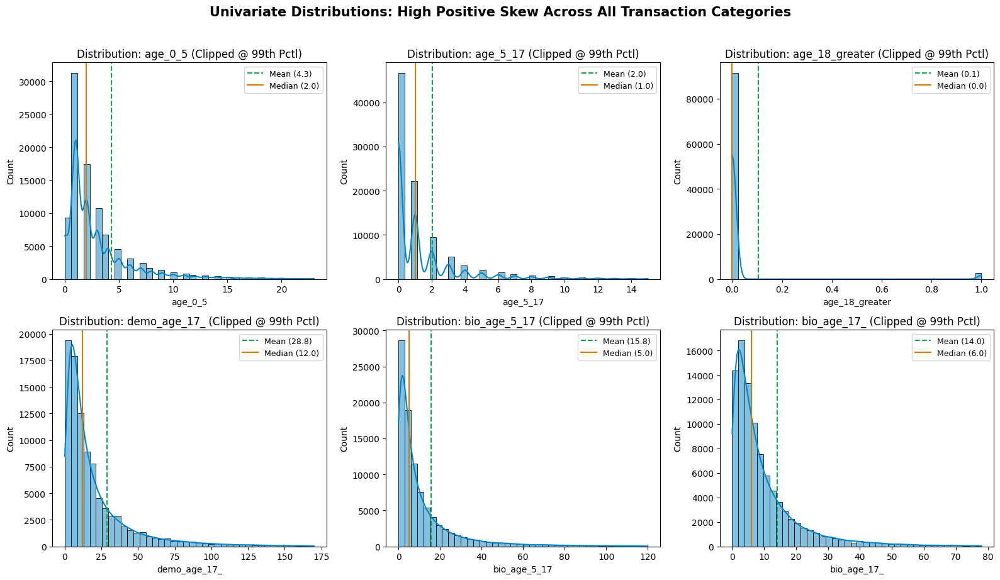

In [202]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_cols = ['age_0_5', 'age_5_17', 'age_18_greater', 'demo_age_17_', 'bio_age_5_17', 'bio_age_17_']

for ax, col in zip(axes.flat, plot_cols):
    clip_val = df[col].quantile(0.99)
    sns.histplot(df[df[col] <= clip_val][col], bins=40, kde=True, ax=ax, color='#0284c7')
    ax.set_title(f'Distribution: {col} (Clipped @ 99th Pctl)')
    ax.axvline(df[col].mean(), color='#16a34a', linestyle='--', label=f"Mean ({df[col].mean():.1f})")
    ax.axvline(df[col].median(), color='#d97706', linestyle='-', label=f"Median ({df[col].median():.1f})")
    ax.legend(fontsize=9)

plt.suptitle('Univariate Distributions: High Positive Skew Across All Transaction Categories', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

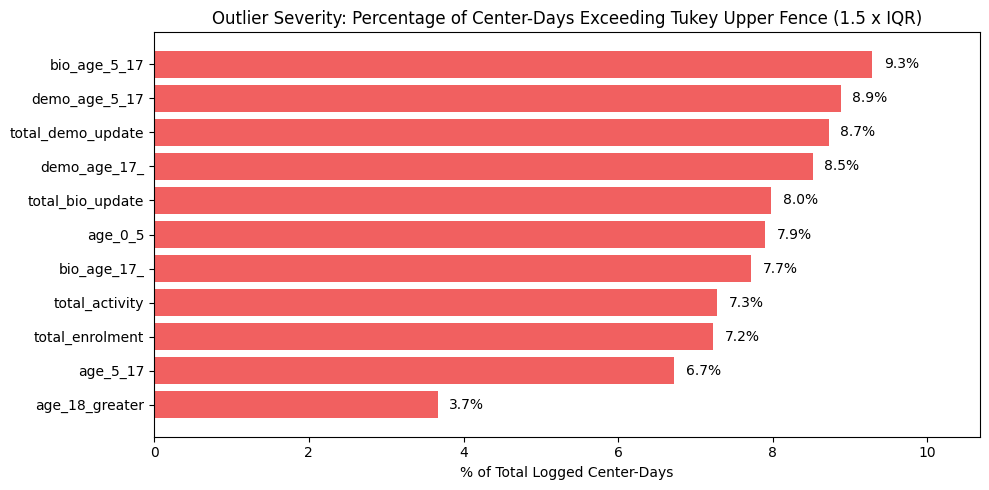

In [203]:
plt.figure(figsize=(10, 5))
sorted_outliers = univariate_df.sort_values('Outlier %', ascending=True)
bars = plt.barh(sorted_outliers['Metric'], sorted_outliers['Outlier %'], color='#ef4444', alpha=0.85)
plt.title('Outlier Severity: Percentage of Center-Days Exceeding Tukey Upper Fence (1.5 x IQR)')
plt.xlabel('% of Total Logged Center-Days')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.15, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10)
plt.xlim(0, max(sorted_outliers['Outlier %']) * 1.15)
plt.tight_layout()
plt.show()

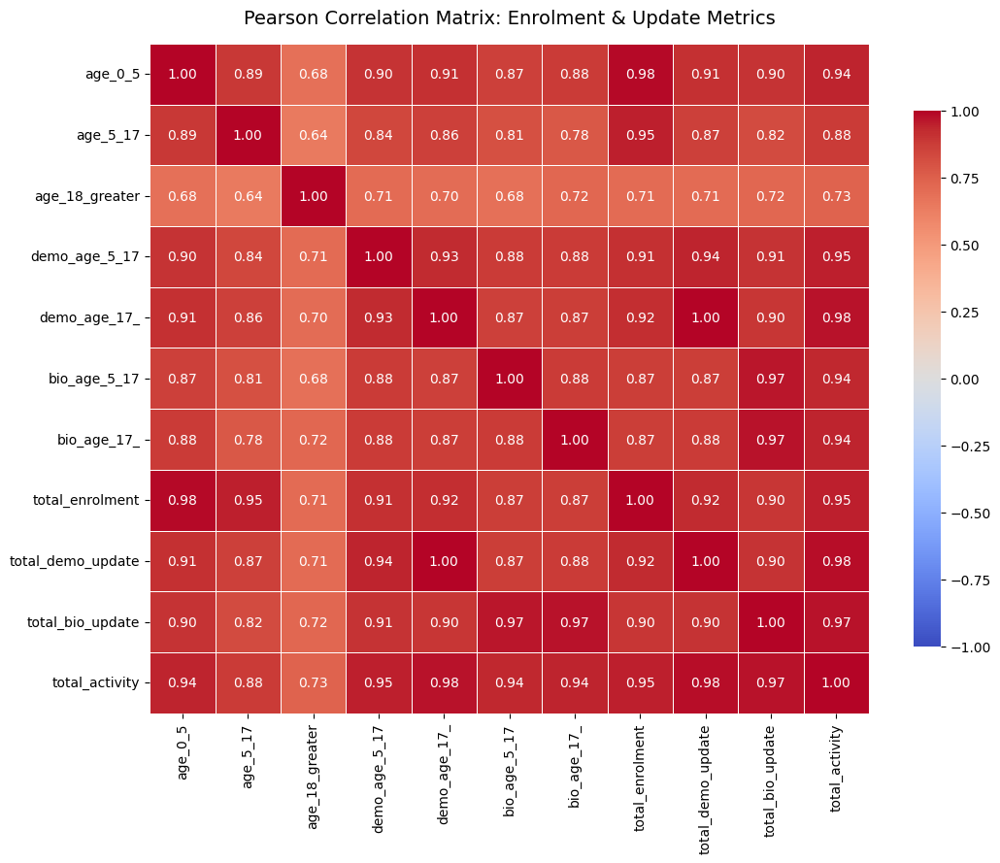

In [204]:
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Pearson Correlation Matrix: Enrolment & Update Metrics', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

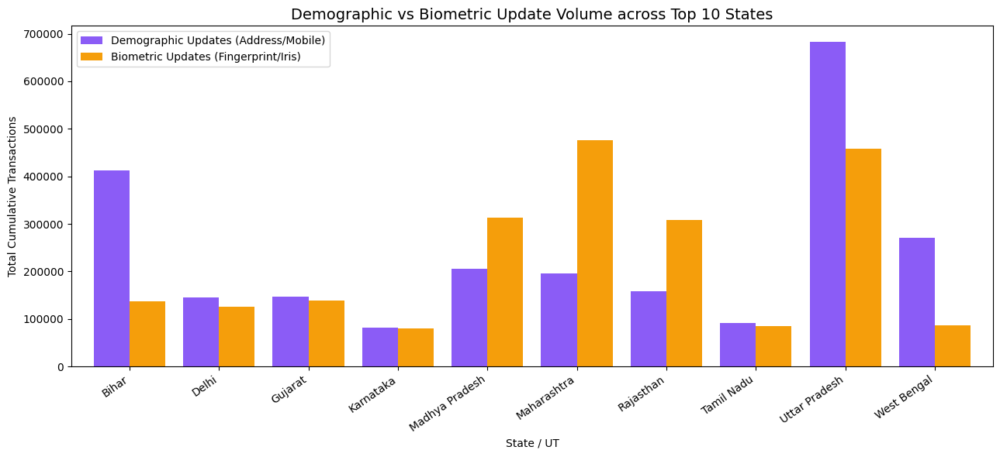

In [207]:
top10_states = df.groupby('state')['total_activity'].sum().nlargest(10).index
state_upd_summary = df[df['state'].isin(top10_states)].groupby('state')[['total_demo_update', 'total_bio_update']].sum()

ax = state_upd_summary.plot(kind='bar', figsize=(13, 6), color=['#8b5cf6', '#f59e0b'], width=0.8)
plt.title('Demographic vs Biometric Update Volume across Top 10 States', fontsize=14)
plt.ylabel('Total Cumulative Transactions')
plt.xlabel('State / UT')
plt.xticks(rotation=35, ha='right')
plt.legend(['Demographic Updates (Address/Mobile)', 'Biometric Updates (Fingerprint/Iris)'])
plt.tight_layout()
plt.show()


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11684\1939504284.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekday_summary.index, y=weekday_summary['sum'], ax=ax1, palette='Blues_r')


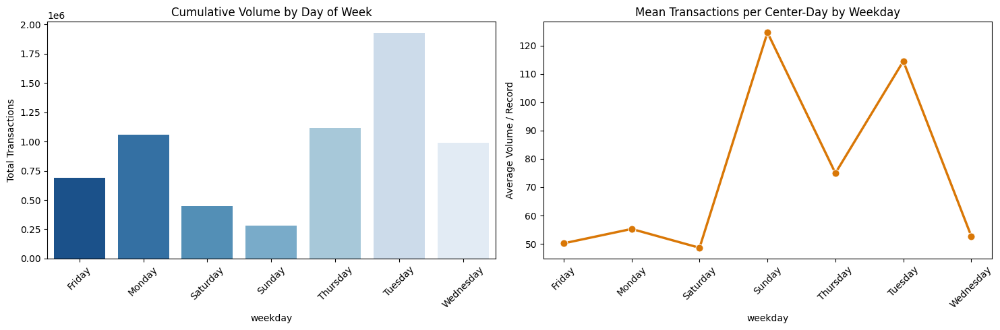

In [210]:
weekday_summary = df.groupby('weekday', observed=False)['total_activity'].agg(['sum', 'mean'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x=weekday_summary.index, y=weekday_summary['sum'], ax=ax1, palette='Blues_r')
ax1.set_title('Cumulative Volume by Day of Week')
ax1.set_ylabel('Total Transactions')
ax1.tick_params(axis='x', rotation=45)

sns.lineplot(x=weekday_summary.index, y=weekday_summary['mean'], ax=ax2, marker='o', color='#d97706', linewidth=2.5, markersize=8)
ax2.set_title('Mean Transactions per Center-Day by Weekday')
ax2.set_ylabel('Average Volume / Record')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

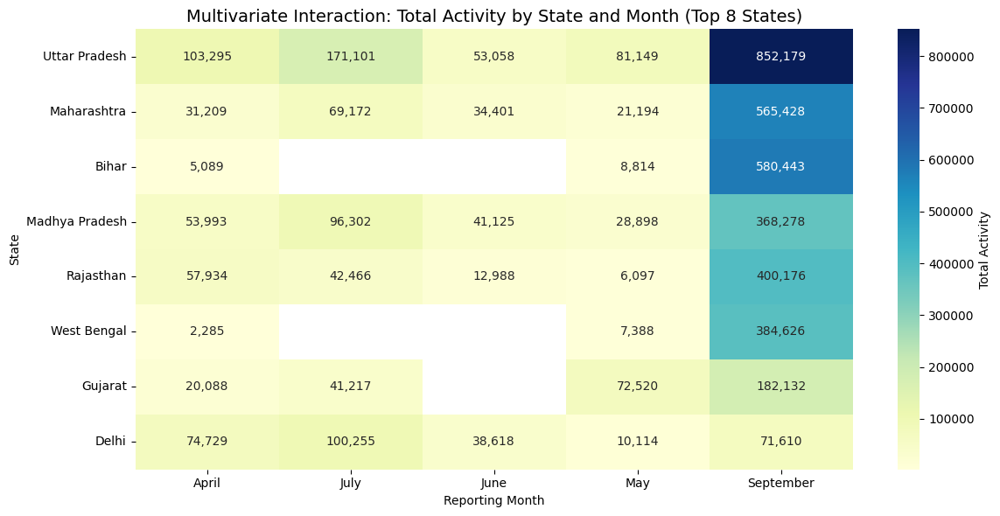

In [211]:
top8_states = df.groupby('state')['total_activity'].sum().nlargest(8).index
pivot_state_month = df[df['state'].isin(top8_states)].pivot_table(
    index='state', columns='month', values='total_activity', aggfunc='sum'
).reindex(top8_states)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_state_month, annot=True, fmt=',.0f', cmap='YlGnBu', cbar_kws={'label': 'Total Activity'})
plt.title('Multivariate Interaction: Total Activity by State and Month (Top 8 States)', fontsize=14)
plt.ylabel('State')
plt.xlabel('Reporting Month')
plt.tight_layout()
plt.show()

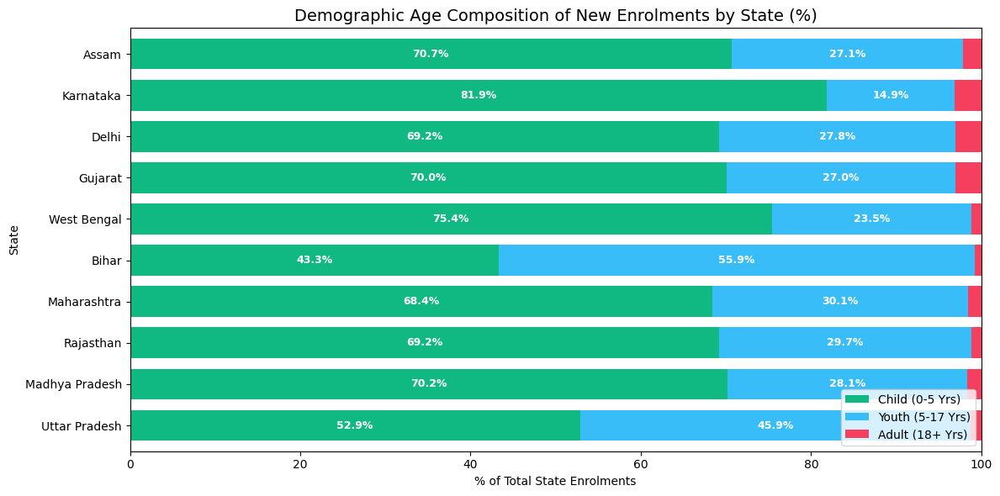

In [212]:
top10_enr_states = df.groupby('state')['total_enrolment'].sum().nlargest(10).index
state_age_mix = df[df['state'].isin(top10_enr_states)].groupby('state')[['age_0_5', 'age_5_17', 'age_18_greater']].sum()
state_age_pct = state_age_mix.div(state_age_mix.sum(axis=1), axis=0) * 100
state_age_pct = state_age_pct.loc[top10_enr_states]

ax = state_age_pct.plot(kind='barh', stacked=True, figsize=(12, 6), color=['#10b981', '#38bdf8', '#f43f5e'], width=0.75)
plt.title('Demographic Age Composition of New Enrolments by State (%)', fontsize=14)
plt.xlabel('% of Total State Enrolments')
plt.ylabel('State')
plt.xlim(0, 100)
plt.legend(['Child (0-5 Yrs)', 'Youth (5-17 Yrs)', 'Adult (18+ Yrs)'], loc='lower right')

for p in ax.patches:
    w = p.get_width()
    if w > 5:
        ax.annotate(f"{w:.1f}%", (p.get_x() + w/2, p.get_y() + p.get_height()/2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

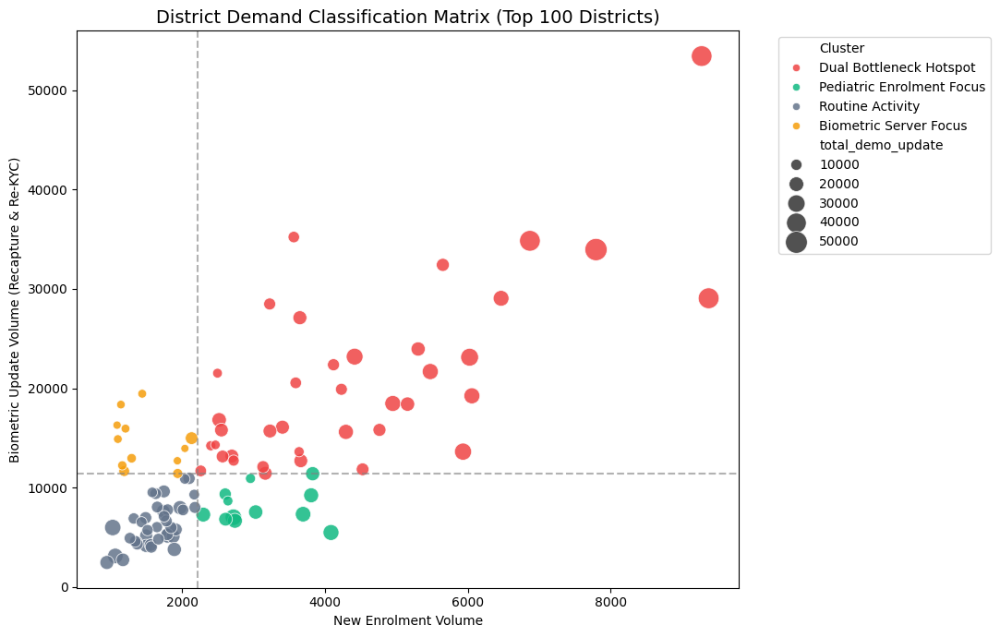

In [213]:
dist_summary = df.groupby(['state', 'district']).agg({
    'total_enrolment': 'sum',
    'total_bio_update': 'sum',
    'total_demo_update': 'sum',
    'total_activity': 'sum',
    'age_0_5': 'sum'
}).reset_index()

top100_districts = dist_summary.sort_values('total_activity', ascending=False).head(100).copy()

med_enr = top100_districts['total_enrolment'].median()
med_bio = top100_districts['total_bio_update'].median()

def classify_cluster(row):
    if row['total_enrolment'] >= med_enr and row['total_bio_update'] >= med_bio:
        return 'Dual Bottleneck Hotspot'
    elif row['total_enrolment'] < med_enr and row['total_bio_update'] >= med_bio:
        return 'Biometric Server Focus'
    elif row['total_enrolment'] >= med_enr and row['total_bio_update'] < med_bio:
        return 'Pediatric Enrolment Focus'
    else:
        return 'Routine Activity'

top100_districts['Cluster'] = top100_districts.apply(classify_cluster, axis=1)

plt.figure(figsize=(11, 7))
palette_map = {
    'Dual Bottleneck Hotspot': '#ef4444',
    'Biometric Server Focus': '#f59e0b',
    'Pediatric Enrolment Focus': '#10b981',
    'Routine Activity': '#64748b'
}

sns.scatterplot(
    data=top100_districts,
    x='total_enrolment',
    y='total_bio_update',
    hue='Cluster',
    palette=palette_map,
    size='total_demo_update',
    sizes=(40, 300),
    alpha=0.85
)

plt.axvline(med_enr, color='grey', linestyle='--', alpha=0.6)
plt.axhline(med_bio, color='grey', linestyle='--', alpha=0.6)
plt.title('District Demand Classification Matrix (Top 100 Districts)', fontsize=14)
plt.xlabel('New Enrolment Volume')
plt.ylabel('Biometric Update Volume (Recapture & Re-KYC)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [215]:
# Infrastructure Pressure Score (IPS) Calculation
import numpy as np
dist_summary['enr_pctl'] = dist_summary['total_enrolment'].rank(pct=True)
dist_summary['child_pctl'] = dist_summary['age_0_5'].rank(pct=True)
dist_summary['bio_pctl'] = dist_summary['total_bio_update'].rank(pct=True)

# Composite Formula
dist_summary['IPS'] = (0.35 * dist_summary['child_pctl'] + 
                       0.35 * dist_summary['bio_pctl'] + 
                       0.30 * dist_summary['enr_pctl']) * 100

total_mobile_kits = 100
top20_priority = dist_summary.sort_values('IPS', ascending=False).head(20).copy()
sum_ips = top20_priority['IPS'].sum()
top20_priority['Allocated_Kits'] = np.maximum(1, (top20_priority['IPS'] / sum_ips * total_mobile_kits).round().astype(int))

print(f"=== OPTIMAL RESOURCE ALLOCATION FOR {total_mobile_kits} MOBILE ENROLMENT/UPDATE UNITS ===")
top20_priority[['state', 'district', 'Allocated_Kits', 'IPS', 'age_0_5', 'total_bio_update', 'total_activity']].head(12)


=== OPTIMAL RESOURCE ALLOCATION FOR 100 MOBILE ENROLMENT/UPDATE UNITS ===


,state,district,Allocated_Kits,IPS,age_0_5,total_bio_update,total_activity
509,Maharashtra,Thane,5,99.927617,5566,53430,106641
826,Uttar Pradesh,Moradabad,5,99.805122,6152,29053,83126
237,Gujarat,Surat,5,99.738307,5170,33955,93434
202,Delhi,West Delhi,5,99.704900,4767,34836,85974
651,Rajasthan,Jaipur,5,99.476615,4662,29049,59404
427,Madhya Pradesh,Indore,5,99.081292,3774,23947,47823
409,Madhya Pradesh,Barwani,5,99.070156,3199,32416,53063
833,Uttar Pradesh,Saharanpur,5,98.997773,3867,21677,52192
766,Uttar Pradesh,Aligarh,5,98.903118,3261,23119,60924
191,Delhi,East Delhi,5,98.563474,3143,23179,55188


## 📋 Executive Takeaways for UIDAI Leadership

1. **Pediatric Institutional Integration:**  
   Child enrolment (0–5) comprises **66.9%** of all new enrolments nationwide, while adult enrolment is saturated at **1.6%**. UIDAI should institutionalize direct birth-registration linkage (CRS) at government hospitals and Anganwadis to capture infants at birth rather than through walk-in center queues.

2. **Mandatory Biometric Recapture In-School Drives (Ages 5 & 15):**  
   Severe biometric update bottlenecks exist in urban hubs (*Thane, Surat, Pune, Jaipur*). By law, children must update biometrics at ages 5 and 15. Partnering with school boards to conduct in-school biometric camps during admission months will alleviate permanent center congestion.

3. **Center Operating Roster Rebalancing:**  
   Weekend center transaction volume is ~80% lower than peak weekdays across all reporting months due to partner closures. Shifting high-demand ASKs to a Tuesday–Saturday operating roster will unlock massive weekend citizen availability.

4. **Self-Service Portal (SSUP) Expansion:**  
   Demographic updates account for >50% of center traffic. Expanding DigiLocker-linked online address and phone verification will allow physical centers to dedicate 100% of booth capacity to biometric capture.
